# Data Cleaning, Master Tables & Time-Series Smoothing

### Objectives of this Notebook
1. Load all 9 raw CSV files from `../RAW_DATA/` without modifying the original files.
2. Inspect table sizes, primary keys, missing values, and fix formatting issues (column name typos, UTF-8 BOM, and duplicate geolocation zip codes).
3. Aggregate child tables (`order_items`, `order_payments`, `order_reviews`) to the `order_id` level so joining tables does not multiply rows.
4. Compute stage-by-stage delivery durations (`approval_hours`, `seller_handling_days`, `carrier_transit_days`, `total_delivery_days`, `days_late`) and straight-line shipping distance (`distance_km`).
5. Export clean, analysis-ready datasets into `../PROCESSED_DATA/`.
6. Apply time-series smoothing methods (Simple Moving Average, Exponentially Weighted Moving Average, and Rolling Median Filter) to daily order volumes and test how different window sizes handle the November 2017 Black Friday spike.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')

RAW_DIR = '../RAW_DATA'
PROC_DIR = '../PROCESSED_DATA'
os.makedirs(PROC_DIR, exist_ok=True)
print('Directories configured:', os.path.abspath(RAW_DIR), '->', os.path.abspath(PROC_DIR))

Directories configured: d:\ACADEMICS\SEM 7\DS3030-DA\PROJECT\RAW_DATA -> d:\ACADEMICS\SEM 7\DS3030-DA\PROJECT\PROCESSED_DATA


--- 
## 1. Load and Profile the 9 Raw Tables 
We load all 9 CSVs from `RAW_DATA/` and build a summary table showing row counts, column counts, duplicate rows, and total missing cells.

In [2]:
orders = pd.read_csv(os.path.join(RAW_DIR, 'olist_orders_dataset.csv'))
items = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_items_dataset.csv'))
payments = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_payments_dataset.csv'))
reviews = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_reviews_dataset.csv'))
customers = pd.read_csv(os.path.join(RAW_DIR, 'olist_customers_dataset.csv'))
sellers = pd.read_csv(os.path.join(RAW_DIR, 'olist_sellers_dataset.csv'))
products = pd.read_csv(os.path.join(RAW_DIR, 'olist_products_dataset.csv'))
geo = pd.read_csv(os.path.join(RAW_DIR, 'olist_geolocation_dataset.csv'))
translations = pd.read_csv(os.path.join(RAW_DIR, 'product_category_name_translation.csv'), encoding='utf-8-sig')

raw_tables = {
    'orders': orders,
    'order_items': items,
    'order_payments': payments,
    'order_reviews': reviews,
    'customers': customers,
    'sellers': sellers,
    'products': products,
    'geolocation': geo,
    'category_translation': translations
}

profile_rows = []
for name, df in raw_tables.items():
    profile_rows.append({
        'Table': name,
        'Rows': len(df),
        'Columns': df.shape[1],
        'Exact Duplicate Rows': int(df.duplicated().sum()),
        'Total Missing Cells': int(df.isna().sum().sum())
    })

profile_df = pd.DataFrame(profile_rows)
profile_df

,Table,Rows,Columns,Exact Duplicate Rows,Total Missing Cells
0,orders,99441,8,0,4908
1,order_items,112650,7,0,0
2,order_payments,103886,5,0,0
3,order_reviews,99224,7,0,145903
4,customers,99441,5,0,0
5,sellers,3095,4,0,0
6,products,32951,9,0,2448
7,geolocation,1000163,5,261831,0
8,category_translation,71,2,0,0


### Check Referential Integrity (Foreign Key Links)
Before joining tables, we verify that every `order_id`, `product_id`, `seller_id`, and `customer_id` links properly across tables.

In [3]:
print('Items linking to valid orders:', items['order_id'].isin(orders['order_id']).mean() * 100, '%')
print('Items linking to valid products:', items['product_id'].isin(products['product_id']).mean() * 100, '%')
print('Items linking to valid sellers:', items['seller_id'].isin(sellers['seller_id']).mean() * 100, '%')
print('Orders linking to valid customers:', orders['customer_id'].isin(customers['customer_id']).mean() * 100, '%')
print('Unique customer_id count:', customers['customer_id'].nunique(), '| Unique customer_unique_id count:', customers['customer_unique_id'].nunique())

Items linking to valid orders: 100.0 %
Items linking to valid products: 100.0 %
Items linking to valid sellers: 100.0 %
Orders linking to valid customers: 100.0 %
Unique customer_id count: 99441 | Unique customer_unique_id count: 96096


--- 
## 2. Clean Individual Tables & Fix Raw Quirks

### 2.1 Products Table: Fix Column Typos & Attach English Category Names
In `olist_products_dataset.csv`, `product_name_lenght` and `product_description_lenght` are misspelled. We rename them, merge the English category names from `product_category_name_translation.csv`, and calculate `product_volume_cm3`.

In [4]:
products_clean = products.rename(columns={
    'product_name_lenght': 'product_name_length',
    'product_description_lenght': 'product_description_length'
}).merge(translations, on='product_category_name', how='left')

products_clean['product_category_name_english'] = products_clean['product_category_name_english'].fillna(
    products_clean['product_category_name'].fillna('unknown')
)

products_clean['product_volume_cm3'] = (
    products_clean['product_length_cm'] *
    products_clean['product_height_cm'] *
    products_clean['product_width_cm']
)

print('Cleaned products shape:', products_clean.shape)
products_clean.head(3)

Cleaned products shape: (32951, 11)


,product_id,product_category_name,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art,10800.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure,2430.0


### 2.2 Geolocation Table: Filter Bounding Box & Compute Zip-Prefix Centroids
`olist_geolocation_dataset.csv` has 1,000,163 rows with multiple GPS points per zip code prefix, plus a few corrupted coordinates outside Brazil (e.g., in the Atlantic Ocean). We filter to Brazil's geographic bounding box (`lat` between `-34` and `6`, `lng` between `-74` and `-34`) and compute the median latitude and longitude for each `geolocation_zip_code_prefix`.

In [5]:
valid_geo = geo[
    (geo['geolocation_lat'].between(-34.0, 6.0)) &
    (geo['geolocation_lng'].between(-74.0, -34.0))
]

geo_centroids = (
    valid_geo.groupby('geolocation_zip_code_prefix', as_index=False)
    .agg(
        lat=('geolocation_lat', 'median'),
        lng=('geolocation_lng', 'median')
    )
)

print(f'Geolocation rows reduced from {len(geo):,} to {len(geo_centroids):,} unique zip prefixes.')

Geolocation rows reduced from 1,000,163 to 19,010 unique zip prefixes.


--- 
## 3. Aggregate Child Tables to `order_id` Level (Preventing Join Multiplication)
If we join `orders` directly to `order_items`, `order_payments`, and `order_reviews`, orders with multiple items or payments get duplicated. Here we aggregate each child table to 1 row per `order_id` first.

In [6]:
# Attach product category and weight/volume to each order item
items_enriched = items.merge(
    products_clean[['product_id', 'product_category_name_english', 'product_weight_g', 'product_volume_cm3']],
    on='product_id',
    how='left'
)

# 1. Aggregate order_items to 1 row per order_id
order_items_agg = items_enriched.groupby('order_id', as_index=False).agg(
    item_count=('order_item_id', 'count'),
    distinct_products=('product_id', 'nunique'),
    distinct_sellers=('seller_id', 'nunique'),
    primary_seller_id=('seller_id', 'first'),
    primary_product_id=('product_id', 'first'),
    primary_category=('product_category_name_english', 'first'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    total_weight_g=('product_weight_g', 'sum'),
    total_volume_cm3=('product_volume_cm3', 'sum'),
    shipping_limit_date=('shipping_limit_date', 'min')
)
order_items_agg['order_total_value'] = order_items_agg['total_price'] + order_items_agg['total_freight']
order_items_agg['freight_ratio'] = order_items_agg['total_freight'] / order_items_agg['total_price'].replace(0, np.nan)

# 2. Aggregate order_payments to 1 row per order_id
payments_sorted = payments.sort_values(['order_id', 'payment_value'], ascending=[True, False])
order_payments_agg = payments_sorted.groupby('order_id', as_index=False).agg(
    payment_total=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max'),
    payment_methods_count=('payment_sequential', 'count'),
    primary_payment_type=('payment_type', 'first')
)

# 3. Aggregate order_reviews to 1 row per order_id (keep latest review if multiple exist)
reviews_sorted = reviews.sort_values('review_creation_date', ascending=False)
order_reviews_agg = reviews_sorted.drop_duplicates(subset=['order_id'], keep='first')[[
    'order_id', 'review_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date'
]].copy()
order_reviews_agg['has_comment'] = order_reviews_agg['review_comment_message'].notna().astype(int)

print('Aggregated child table row counts:')
print('  order_items_agg:   ', len(order_items_agg))
print('  order_payments_agg:', len(order_payments_agg))
print('  order_reviews_agg: ', len(order_reviews_agg))

Aggregated child table row counts:
  order_items_agg:    98666
  order_payments_agg: 99440
  order_reviews_agg:  98673


--- 
## 4. Build `master_orders.csv`: Delivery Durations & Haversine Distance
We merge `orders` with `customers`, the aggregated child tables, `sellers`, and `geo_centroids`, then compute:
* `approval_hours`: Hours from purchase to payment approval
* `seller_handling_days`: Days from approval to carrier handover
* `carrier_transit_days`: Days from carrier handover to customer delivery
* `total_delivery_days`: Total days from purchase to customer delivery
* `days_late`: Actual delivery date minus estimated delivery date (negative = early, positive = late)
* `distance_km`: Haversine distance between seller zip code centroid and customer zip code centroid

In [7]:
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2.0) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

master_orders = (
    orders
    .merge(customers, on='customer_id', how='left')
    .merge(order_items_agg, on='order_id', how='left')
    .merge(order_payments_agg, on='order_id', how='left')
    .merge(order_reviews_agg, on='order_id', how='left')
    .merge(
        sellers.rename(columns={'seller_id': 'primary_seller_id'}),
        on='primary_seller_id',
        how='left'
    )
    .merge(
        geo_centroids.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix', 'lat': 'cust_lat', 'lng': 'cust_lng'}),
        on='customer_zip_code_prefix',
        how='left'
    )
    .merge(
        geo_centroids.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix', 'lat': 'seller_lat', 'lng': 'seller_lng'}),
        on='seller_zip_code_prefix',
        how='left'
    )
)

assert len(master_orders) == len(orders), 'Row count changed during join!'

# Parse timestamp columns
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'shipping_limit_date'
]
for col in date_cols:
    master_orders[col] = pd.to_datetime(master_orders[col], errors='coerce')

# Compute stage durations
master_orders['approval_hours'] = (
    (master_orders['order_approved_at'] - master_orders['order_purchase_timestamp']).dt.total_seconds() / 3600.0
)
master_orders['seller_handling_days'] = (
    (master_orders['order_delivered_carrier_date'] - master_orders['order_approved_at']).dt.total_seconds() / 86400.0
)
master_orders['carrier_transit_days'] = (
    (master_orders['order_delivered_customer_date'] - master_orders['order_delivered_carrier_date']).dt.total_seconds() / 86400.0
)
master_orders['total_delivery_days'] = (
    (master_orders['order_delivered_customer_date'] - master_orders['order_purchase_timestamp']).dt.total_seconds() / 86400.0
)
master_orders['estimated_delivery_days'] = (
    (master_orders['order_estimated_delivery_date'] - master_orders['order_purchase_timestamp']).dt.total_seconds() / 86400.0
)
master_orders['days_late'] = (
    (master_orders['order_delivered_customer_date'] - master_orders['order_estimated_delivery_date']).dt.total_seconds() / 86400.0
)
master_orders['seller_shipped_late'] = (
    master_orders['order_delivered_carrier_date'] > master_orders['shipping_limit_date']
).astype(int)

# Flag negative duration timestamp anomalies (e.g., carrier date recorded before approval date)
master_orders['valid_timestamps_flag'] = (
    (master_orders['approval_hours'] >= 0) &
    (master_orders['seller_handling_days'] >= 0) &
    (master_orders['carrier_transit_days'] >= 0) &
    (master_orders['total_delivery_days'] >= 0)
).astype(int)

master_orders['is_late'] = (master_orders['days_late'] > 0).astype(float)
master_orders.loc[master_orders['days_late'].isna(), 'is_late'] = np.nan

# Lateness buckets for downstream tolerance analysis
bins = [-np.inf, -1.0, 0.0, 3.0, 7.0, np.inf]
labels = ['Early (>1d early)', 'On Time (-1d to 0d)', '1-3 Days Late', '4-7 Days Late', '>7 Days Late']
master_orders['lateness_bucket'] = pd.cut(master_orders['days_late'], bins=bins, labels=labels)

# Compute seller-to-customer Haversine distance (km)
master_orders['distance_km'] = haversine_km(
    master_orders['seller_lat'], master_orders['seller_lng'],
    master_orders['cust_lat'], master_orders['cust_lng']
)
master_orders['is_cross_state'] = (master_orders['seller_state'] != master_orders['customer_state']).astype(int)

# Calendar columns
master_orders['purchase_date'] = master_orders['order_purchase_timestamp'].dt.date
master_orders['purchase_year'] = master_orders['order_purchase_timestamp'].dt.year
master_orders['purchase_month'] = master_orders['order_purchase_timestamp'].dt.month
master_orders['purchase_dayofweek'] = master_orders['order_purchase_timestamp'].dt.dayofweek
master_orders['purchase_hour'] = master_orders['order_purchase_timestamp'].dt.hour

print('master_orders created successfully! Shape:', master_orders.shape)

master_orders created successfully! Shape: (99441, 59)


### Research Question 1 Check: Where is Time Lost Between Purchase and Delivery?
Let's compare the average and median time spent in **Payment Approval**, **Seller Handling**, and **Carrier Transit** for On-Time vs. Late delivered orders.

In [8]:
delivered_valid = master_orders[
    (master_orders['order_status'] == 'delivered') &
    (master_orders['valid_timestamps_flag'] == 1)
].copy()

stage_summary = delivered_valid.groupby('is_late')[[
    'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'estimated_delivery_days', 'distance_km', 'review_score'
]].agg(['count', 'mean', 'median']).round(2)

stage_summary.index = ['On-Time Orders (is_late=0)', 'Late Orders (is_late=1)']
stage_summary

approval_hours               seller_handling_days  \
                                    count   mean median                count   
On-Time Orders (is_late=0)          87290   9.44   0.33                87290   
Late Orders (is_late=1)              7792  12.05   0.41                 7792   

                                        carrier_transit_days                \
                            mean median                count   mean median   
On-Time Orders (is_late=0)  2.63   1.78                87290   7.91   6.93   
Late Orders (is_late=1)     5.35   3.02                 7792  25.68  23.92   

                           total_delivery_days                \
                                         count   mean median   
On-Time Orders (is_late=0)               87290  10.93   9.79   
Late Orders (is_late=1)                   7792  31.53  29.18   

                           estimated_delivery_days               distance_km  \
                                             count   mean median       count   
On-Time Orders (is_late=0)                   87290  23.90  23.30       86869   
Late Orders (is_late=1)                       7792  21.97  22.22        7741   

                                           review_score               
                              mean  median        count  mean median  
On-Time Orders (is_late=0)  588.29  426.63        86816  4.29    5.0  
Late Orders (is_late=1)     736.55  511.24         7627  2.56    2.0

--- 
## 5. Build `master_sellers.csv` (1 Row per Seller)
We aggregate order and item metrics per seller so that we can analyse seller behaviour directly.

In [9]:
# Merge item-level records with order-level delivery & review metrics
item_order_merged = items_enriched.merge(
    master_orders[[
        'order_id', 'order_status', 'approval_hours', 'seller_handling_days',
        'carrier_transit_days', 'total_delivery_days', 'days_late', 'is_late',
        'seller_shipped_late', 'review_score', 'customer_state', 'distance_km', 'valid_timestamps_flag'
    ]],
    on='order_id',
    how='left'
)

master_sellers = (
    item_order_merged.groupby('seller_id', as_index=False)
    .agg(
        total_orders=('order_id', 'nunique'),
        total_items=('order_item_id', 'count'),
        total_revenue=('price', 'sum'),
        total_freight=('freight_value', 'sum'),
        avg_price=('price', 'mean'),
        avg_freight=('freight_value', 'mean'),
        avg_weight_g=('product_weight_g', 'mean'),
        avg_handling_days=('seller_handling_days', 'mean'),
        median_handling_days=('seller_handling_days', 'median'),
        avg_transit_days=('carrier_transit_days', 'mean'),
        avg_delivery_days=('total_delivery_days', 'mean'),
        avg_days_late=('days_late', 'mean'),
        late_rate=('is_late', 'mean'),
        seller_shipped_late_rate=('seller_shipped_late', 'mean'),
        avg_review_score=('review_score', 'mean'),
        low_review_rate=('review_score', lambda s: (s <= 2).mean() if s.notna().any() else np.nan),
        distinct_categories=('product_category_name_english', 'nunique'),
        states_served=('customer_state', 'nunique'),
        avg_distance_km=('distance_km', 'mean')
    )
    .merge(sellers, on='seller_id', how='left')
)

master_sellers['freight_ratio'] = master_sellers['total_freight'] / master_sellers['total_revenue'].replace(0, np.nan)

# Compute share of orders shipped outside seller's own state
item_order_merged = item_order_merged.merge(sellers[['seller_id', 'seller_state']], on='seller_id', how='left')
item_order_merged['cross_state'] = (item_order_merged['seller_state'] != item_order_merged['customer_state']).astype(int)
cross_state_df = item_order_merged.groupby('seller_id', as_index=False)['cross_state'].mean().rename(columns={'cross_state': 'cross_state_share'})
master_sellers = master_sellers.merge(cross_state_df, on='seller_id', how='left')

print('master_sellers shape:', master_sellers.shape)
master_sellers.head(5)

master_sellers shape: (3095, 25)


,seller_id,total_orders,total_items,total_revenue,total_freight,avg_price,avg_freight,avg_weight_g,avg_handling_days,median_handling_days,avg_transit_days,avg_delivery_days,avg_days_late,late_rate,seller_shipped_late_rate,avg_review_score,low_review_rate,distinct_categories,states_served,avg_distance_km,seller_zip_code_prefix,seller_city,seller_state,freight_ratio,cross_state_share
0,0015a82c2db000af6aaaf3ae2ecb0532,3,3,2685.00,63.06,895.000000,21.020000,11800.000000,2.804352,1.728322,7.433295,10.793885,-15.593380,0.000000,0.000000,3.666667,0.333333,1,2,606.589740,9080,santo andre,SP,0.023486,1.000000
1,001cca7ae9ae17fb1caed9dfb1094831,200,239,25080.03,8854.14,104.937364,37.046611,8973.849372,2.179816,1.671863,10.459199,13.096632,-12.569366,0.055556,0.054393,3.902542,0.188285,2,18,807.971737,29156,cariacica,ES,0.353035,0.974895
2,001e6ad469a905060d959994f1b41e4f,1,1,250.00,17.94,250.000000,17.940000,750.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,1.000000,1,1,394.481094,24754,sao goncalo,RJ,0.071760,1.000000
3,002100f778ceb8431b7a1020ff7ab48f,51,55,1234.50,793.66,22.445455,14.430182,331.818182,3.542166,2.733380,11.697006,16.192371,-7.395119,0.166667,0.090909,3.981818,0.145455,1,13,517.647972,14405,franca,SP,0.642900,0.563636
4,003554e2dce176b5555353e4f3555ac8,1,1,120.00,19.38,120.000000,19.380000,1200.000000,0.523623,0.523623,4.110243,4.646806,-26.066794,0.000000,0.000000,5.000000,0.000000,1,1,936.393081,74565,goiania,GO,0.161500,1.000000


--- 
## 6. Time-Series Noise Removal & Smoothing
Daily order counts and daily revenue have strong weekday-vs-weekend noise. Here we aggregate Daily orders from January 2017 to August 2018, and apply three smoothing methods:
1. **Simple Moving Average (SMA):** 7-day, 14-day, and 30-day windows
2. **Exponentially Weighted Moving Average (EWMA):** `span=7` and `span=14`
3. **Rolling Median Filter:** 7-day and 14-day windows

We also inspect **November 24, 2017 (Black Friday)** to see how wider windows over-smooth real promotional events.

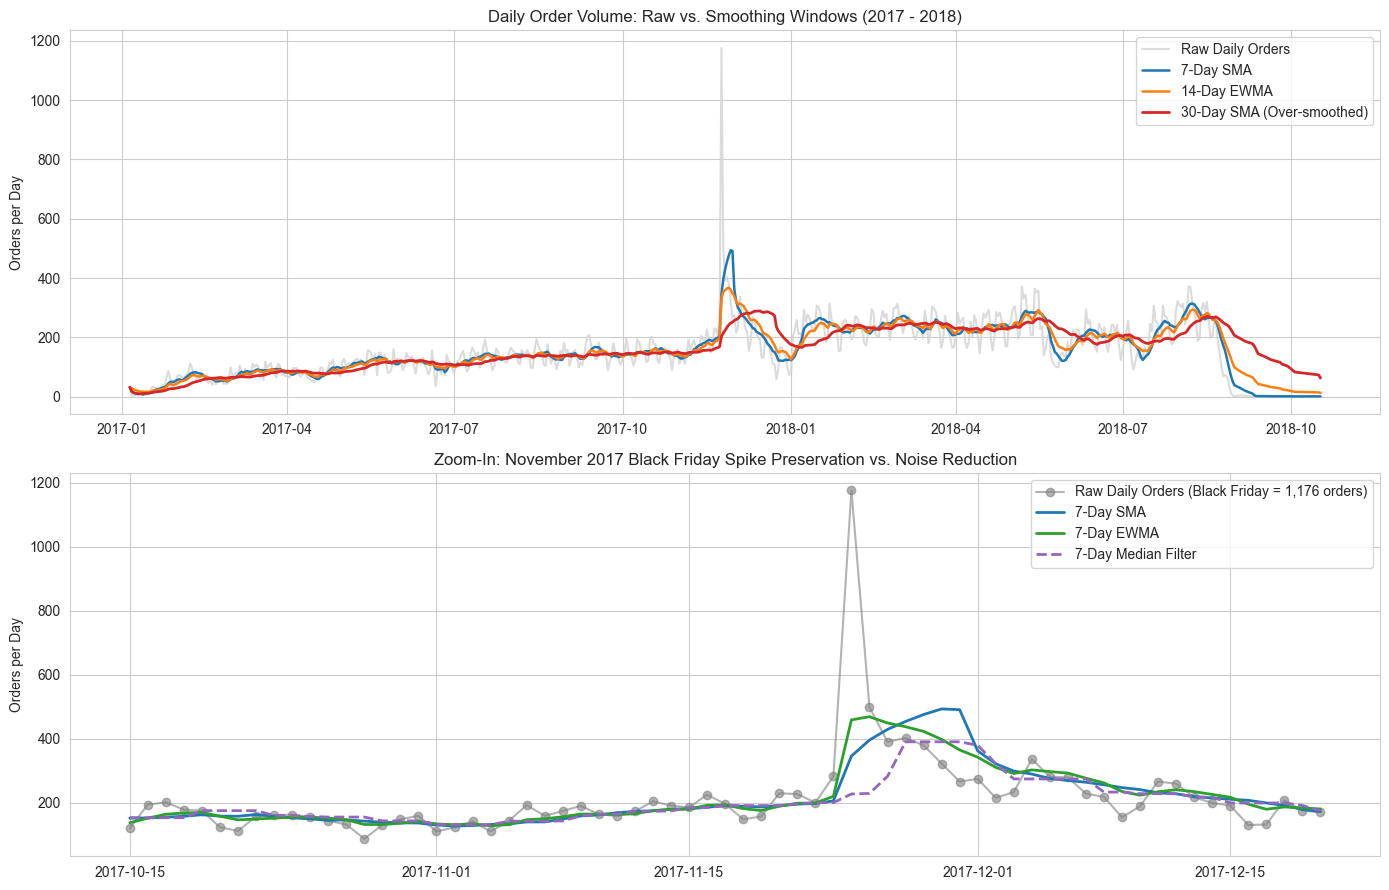

In [10]:
daily_ts = (
    master_orders[master_orders['order_purchase_timestamp'] >= '2017-01-01']
    .groupby('purchase_date', as_index=False)
    .agg(
        raw_orders=('order_id', 'count'),
        raw_revenue=('total_price', 'sum'),
        late_rate=('is_late', 'mean'),
        avg_review=('review_score', 'mean')
    )
)
daily_ts['purchase_date'] = pd.to_datetime(daily_ts['purchase_date'])
daily_ts = daily_ts.sort_values('purchase_date').reset_index(drop=True)

# Apply SMA, EWMA, and Rolling Median
for w in [7, 14, 30]:
    daily_ts[f'sma_{w}d'] = daily_ts['raw_orders'].rolling(window=w, min_periods=1).mean()
    daily_ts[f'ewma_{w}d'] = daily_ts['raw_orders'].ewm(span=w, adjust=False).mean()
    daily_ts[f'median_{w}d'] = daily_ts['raw_orders'].rolling(window=w, min_periods=1).median()

# Plot Raw vs Smoothed Daily Orders
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False)

# Top plot: Full timeline comparing Raw, 7d SMA, 14d EWMA, and 30d SMA
axes[0].plot(daily_ts['purchase_date'], daily_ts['raw_orders'], color='lightgray', alpha=0.8, label='Raw Daily Orders')
axes[0].plot(daily_ts['purchase_date'], daily_ts['sma_7d'], color='#1f77b4', linewidth=1.8, label='7-Day SMA')
axes[0].plot(daily_ts['purchase_date'], daily_ts['ewma_14d'], color='#ff7f0e', linewidth=1.8, label='14-Day EWMA')
axes[0].plot(daily_ts['purchase_date'], daily_ts['sma_30d'], color='#d62728', linewidth=2.0, label='30-Day SMA (Over-smoothed)')
axes[0].set_title('Daily Order Volume: Raw vs. Smoothing Windows (2017 - 2018)')
axes[0].set_ylabel('Orders per Day')
axes[0].legend()

# Bottom plot: Zoom into November 2017 (Black Friday spike)
nov_mask = (daily_ts['purchase_date'] >= '2017-10-15') & (daily_ts['purchase_date'] <= '2017-12-20')
sub = daily_ts[nov_mask]
axes[1].plot(sub['purchase_date'], sub['raw_orders'], marker='o', color='gray', alpha=0.6, label='Raw Daily Orders (Black Friday = 1,176 orders)')
axes[1].plot(sub['purchase_date'], sub['sma_7d'], linewidth=2, color='#1f77b4', label='7-Day SMA')
axes[1].plot(sub['purchase_date'], sub['ewma_7d'], linewidth=2, color='#2ca02c', label='7-Day EWMA')
axes[1].plot(sub['purchase_date'], sub['median_7d'], linewidth=2, linestyle='--', color='#9467bd', label='7-Day Median Filter')
axes[1].set_title('Zoom-In: November 2017 Black Friday Spike Preservation vs. Noise Reduction')
axes[1].set_ylabel('Orders per Day')
axes[1].legend()

plt.tight_layout()
plt.show()

--- 
## 7. Save All Cleaned Files to `PROCESSED_DATA/`
Finally, we export all cleaned datasets to `../PROCESSED_DATA/` so Notebooks 02, 03, 04, and 05 can load them directly.

In [11]:
master_orders.to_csv(os.path.join(PROC_DIR, 'master_orders.csv'), index=False)
master_sellers.to_csv(os.path.join(PROC_DIR, 'master_sellers.csv'), index=False)
products_clean.to_csv(os.path.join(PROC_DIR, 'cleaned_products.csv'), index=False)
items_enriched.to_csv(os.path.join(PROC_DIR, 'cleaned_items.csv'), index=False)
order_reviews_agg.to_csv(os.path.join(PROC_DIR, 'cleaned_reviews.csv'), index=False)
daily_ts.to_csv(os.path.join(PROC_DIR, 'daily_orders_smoothed.csv'), index=False)

for fname in sorted(os.listdir(PROC_DIR)):
    fpath = os.path.join(PROC_DIR, fname)
    size_mb = os.path.getsize(fpath) / (1024 * 1024)
    print(f'Saved {fname:<28} ({size_mb:.2f} MB)')

Saved master_sellers.csv           (0.86 MB)
